<a href="https://colab.research.google.com/github/Visweash1234/Applied-Data-Science-1/blob/main/Assignment_2_Title_Clustering_and_Model_Fitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from __future__ import annotations

import json
import os
import re
import time
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

# ---------------------------------------------------------------------------
# Global Styling & Domain Constants
# ---------------------------------------------------------------------------
DATASET_ID = "d_8b84c4ee58e3cfc0ece0d773c8ca6abc"
DATA_GOV_URL = f"https://data.gov.sg/datasets/{DATASET_ID}/view"

PALETTE = {
    "navy": "#0F172A",
    "slate": "#475569",
    "teal": "#0D9488",
    "coral": "#E11D48",
    "amber": "#D97706",
    "indigo": "#4F46E5",
    "light_bg": "#F8FAFC",
    "grid": "#CBD5E1",
}

PRIME_CENTRAL_TOWNS = {
    "CENTRAL AREA",
    "BUKIT TIMAH",
    "BISHAN",
    "QUEENSTOWN",
    "BUKIT MERAH",
    "KALLANG/WHAMPOA",
    "MARINE PARADE",
    "TOA PAYOH",
}

MATURE_HEARTLAND_TOWNS = {
    "ANG MO KIO",
    "BEDOK",
    "CLEMENTI",
    "GEYLANG",
    "PASIR RIS",
    "SERANGOON",
    "TAMPINES",
}

plt.rcParams.update(
    {
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "font.sans-serif": "DejaVu Sans",
        "axes.edgecolor": PALETTE["grid"],
        "axes.linewidth": 0.9,
        "axes.titlesize": 12.5,
        "axes.titleweight": "bold",
        "axes.labelsize": 10.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
    }
)




In [2]:
# ---------------------------------------------------------------------------
# 1. Data Ingestion (Live Official data.gov.sg API + Local CSV Support)
# ---------------------------------------------------------------------------
def fetch_hdb_resale_data(
    local_csv_path: Optional[str] = None,
    cache_path: str = "hdb_resale_2017_onwards.csv",
    max_poll_attempts: int = 12,
) -> pd.DataFrame:
    """Load official Singapore HDB resale dataset (Jan 2017 - Nov 2026).

    Priority order:
        1. Explicit ``local_csv_path`` if supplied and present on disk.
        2. Cached local CSV (``cache_path``) if previously downloaded.
        3. Official data.gov.sg v1 initiate/poll CSV download API (no key).
        4. Fallback to paginated data.gov.sg ``datastore_search`` API.

    Args:
        local_csv_path: Optional path to a manually downloaded CSV from data.gov.sg.
        cache_path: Local path to cache the downloaded CSV for reproducibility.
        max_poll_attempts: Maximum polling retries for signed S3 download URL.

    Returns:
        Raw pandas DataFrame containing HDB resale transactions.
    """
    if local_csv_path and os.path.exists(local_csv_path):
        print(f"[INFO] Loading local CSV: {local_csv_path}")
        return pd.read_csv(local_csv_path)

    if os.path.exists(cache_path):
        print(f"[INFO] Loading cached official CSV: {cache_path}")
        return pd.read_csv(cache_path)

    # Attempt 1: Official data.gov.sg CSV download pipeline (full dataset)
    init_url = (
        f"https://api-open.data.gov.sg/v1/public/api/datasets/"
        f"{DATASET_ID}/initiate-download"
    )
    poll_url = (
        f"https://api-open.data.gov.sg/v1/public/api/datasets/"
        f"{DATASET_ID}/poll-download"
    )

    try:
        print("[INFO] Requesting full official HDB CSV from data.gov.sg...")
        requests.get(init_url, timeout=20)
        for attempt in range(1, max_poll_attempts + 1):
            resp = requests.get(poll_url, timeout=20)
            payload = resp.json()
            data_block = payload.get("data", {})
            download_url = data_block.get("url")
            if download_url:
                print(f"[INFO] Download link ready on attempt {attempt}. Fetching...")
                df = pd.read_csv(download_url)
                df.to_csv(cache_path, index=False)
                print(f"[INFO] Saved {len(df):,} official records to {cache_path}")
                return df
            time.sleep(2)
    except Exception as exc:
        print(f"[WARN] Full CSV poll endpoint unavailable ({exc}). Switching to API.")

    # Attempt 2: Fallback via paginated datastore_search (latest 30,000 rows)
    print("[INFO] Fetching latest records via data.gov.sg datastore_search...")
    records: List[Dict] = []
    limit = 5000
    for offset in range(0, 30000, limit):
        api_url = (
            "https://data.gov.sg/api/action/datastore_search"
            f"?resource_id={DATASET_ID}&sort=month%20desc&limit={limit}&offset={offset}"
        )
        resp = requests.get(api_url, timeout=30)
        resp.raise_for_status()
        batch = resp.json()["result"]["records"]
        if not batch:
            break
        records.extend(batch)
        time.sleep(0.3)

    if not records:
        raise RuntimeError(
            "Unable to download HDB dataset automatically. Please download the CSV "
            f"manually from {DATA_GOV_URL} and pass its path to local_csv_path."
        )

    df = pd.DataFrame(records)
    df.to_csv(cache_path, index=False)
    print(f"[INFO] Saved {len(df):,} API records to {cache_path}")
    return df

In [3]:
# ---------------------------------------------------------------------------
# 2. Data Cleaning, Regex Parsing & Feature Engineering
# ---------------------------------------------------------------------------
def parse_storey_midpoint(storey_str: str) -> float:
    """Convert HDB storey range strings (e.g., '07 TO 09') to numeric midpoint.

    Args:
        storey_str: Raw storey range string from HDB records.

    Returns:
        Midpoint floor level as float, or NaN if unparseable.
    """
    if not isinstance(storey_str, str):
        return np.nan
    nums = re.findall(r"\d+", storey_str)
    if len(nums) >= 2:
        return (float(nums[0]) + float(nums[1])) / 2.0
    if len(nums) == 1:
        return float(nums[0])
    return np.nan


def parse_remaining_lease(lease_str: object) -> float:
    """Convert HDB remaining lease strings (e.g., '61 years 04 months') to years.

    Handles both 'XX years YY months' and 'XX years' edge formats cleanly.

    Args:
        lease_str: Raw remaining lease string or numeric value.

    Returns:
        Remaining lease duration in continuous years.
    """
    if pd.isna(lease_str):
        return np.nan
    text = str(lease_str).strip().lower()
    yr_match = re.search(r"(\d+)\s*year", text)
    mo_match = re.search(r"(\d+)\s*month", text)
    if yr_match:
        years = float(yr_match.group(1))
        months = float(mo_match.group(1)) if mo_match else 0.0
        return round(years + months / 12.0, 3)
    try:
        return float(text)
    except ValueError:
        return np.nan


def map_region_tier(town: str) -> str:
    """Map Singapore HDB towns into three strategic real-estate tiers.

    Args:
        town: Uppercase HDB town name.

    Returns:
        One of 'Prime / Central', 'Mature Heartland', or 'Non-Mature Heartland'.
    """
    clean_town = str(town).strip().upper()
    if clean_town in PRIME_CENTRAL_TOWNS:
        return "Prime / Central"
    if clean_town in MATURE_HEARTLAND_TOWNS:
        return "Mature Heartland"
    return "Non-Mature Heartland"


def clean_and_engineer_features(
    raw_df: pd.DataFrame,
    min_year: int = 2022,
) -> Tuple[pd.DataFrame, Dict[str, object]]:
    """Clean raw HDB transactions and construct domain-relevant features.

    Steps performed:
        1. Normalize column names and drop internal API keys (e.g., '_id').
        2. Cast numeric fields stored as strings ('floor_area_sqm',
           'lease_commence_date', 'resale_price').
        3. Parse 'month' -> 'year', 'month_num', 'months_since_start'.
        4. Filter to recent market regime (year >= min_year) to avoid pre-COVID
           structural break distortion.
        5. Regex-parse 'storey_range' and 'remaining_lease'.
        6. Deduplicate exact repeated transaction rows and audit missingness.
        7. Compute IQR outlier statistics (documenting legitimate million-dollar
           flats rather than blindly deleting true market signals).
        8. Engineer 'price_per_sqm', 'flat_age_years', and 'region_tier'.

    Args:
        raw_df: Raw DataFrame from data.gov.sg.
        min_year: Earliest transaction year to include in modeling scope.

    Returns:
        Tuple of (cleaned DataFrame, cleaning audit dictionary).
    """
    df = raw_df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    if "_id" in df.columns:
        df = df.drop(columns=["_id"])

    raw_rows = len(df)
    raw_missing = int(df.isna().sum().sum())

    # Standardize text columns
    text_cols = ["town", "flat_type", "flat_model", "storey_range", "street_name"]
    for col in text_cols:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.upper()

    # Cast numeric columns stored as strings
    for col in ["floor_area_sqm", "lease_commence_date", "resale_price"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Temporal parsing
    dt = pd.to_datetime(df["month"], format="%Y-%m", errors="coerce")
    df["year"] = dt.dt.year
    df["month_num"] = dt.dt.month

    # Scope to post-2022 modern HDB market regime
    df = df[df["year"] >= min_year].copy()
    scoped_rows = len(df)

    # Deduplication
    duplicate_count = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()

    # Regex feature parsing
    df["storey_midpoint"] = df["storey_range"].apply(parse_storey_midpoint)
    df["remaining_lease_years"] = df["remaining_lease"].apply(parse_remaining_lease)

    # Drop any rows with unparseable core modeling fields
    core_fields = [
        "floor_area_sqm",
        "resale_price",
        "storey_midpoint",
        "remaining_lease_years",
        "year",
    ]
    pre_dropna = len(df)
    df = df.dropna(subset=core_fields).copy()
    dropped_nulls = pre_dropna - len(df)

    # Domain validity filter (positive area, realistic lease <= 99 years)
    df = df[
        (df["floor_area_sqm"] > 20)
        & (df["resale_price"] > 50_000)
        & (df["remaining_lease_years"].between(1, 99.5))
    ].copy()

    # Feature engineering
    df["months_since_start"] = (df["year"] - min_year) * 12 + (df["month_num"] - 1)
    df["flat_age_years"] = (99.0 - df["remaining_lease_years"]).clip(lower=0.0)
    df["price_per_sqm"] = df["resale_price"] / df["floor_area_sqm"]
    df["region_tier"] = df["town"].apply(map_region_tier)
    df["is_million_dollar"] = (df["resale_price"] >= 1_000_000).astype(int)

    # IQR Outlier Audit (documented; legitimate luxury units retained)
    q1 = df["resale_price"].quantile(0.25)
    q3 = df["resale_price"].quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    iqr_high_outliers = int((df["resale_price"] > upper_fence).sum())
    million_dollar_count = int(df["is_million_dollar"].sum())

    # Remove extreme rare flat types with negligible sample size (<0.1%)
    valid_types = ["2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]
    df = df[df["flat_type"].isin(valid_types)].copy()
    df.reset_index(drop=True, inplace=True)

    audit = {
        "raw_rows_total": raw_rows,
        "raw_missing_cells": raw_missing,
        "scoped_rows_2022_plus": scoped_rows,
        "exact_duplicates_removed": duplicate_count,
        "unparseable_rows_dropped": dropped_nulls,
        "final_clean_rows": len(df),
        "unique_towns": int(df["town"].nunique()),
        "date_range": f"{df['month'].min()} to {df['month'].max()}",
        "iqr_upper_fence_sgd": round(float(upper_fence), 0),
        "iqr_high_outliers_retained": iqr_high_outliers,
        "million_dollar_transactions": million_dollar_count,
        "million_dollar_share_pct": round(100.0 * million_dollar_count / len(df), 2),
        "median_resale_price_sgd": round(float(df["resale_price"].median()), 0),
        "mean_resale_price_sgd": round(float(df["resale_price"].mean()), 0),
        "median_price_per_sqm": round(float(df["price_per_sqm"].median()), 0),
    }
    return df, audit

In [4]:
# ---------------------------------------------------------------------------
# 3. Dedicated PEP-8 Visualization Functions (5 Publication-Grade Plots)
# ---------------------------------------------------------------------------
def plot_categorical_price_by_flat_type_and_town(
    df: pd.DataFrame,
    output_path: str = "plot1_categorical_market_overview.png",
) -> None:
    """Plot 1 (Categorical): Price distribution by Flat Type & Top/Bottom Towns.

    Args:
        df: Cleaned HDB resale DataFrame.
        output_path: Output PNG file path.
    """
    flat_order = ["2 ROOM", "3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"]
    town_stats = (
        df.groupby(["town", "region_tier"])["price_per_sqm"]
        .median()
        .reset_index()
        .sort_values("price_per_sqm", ascending=False)
    )
    top_bottom = pd.concat([town_stats.head(7), town_stats.tail(6)]).sort_values(
        "price_per_sqm", ascending=True
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [1.05, 1.15]})

    # Left panel: Boxplot by Flat Type
    sns.boxplot(
        data=df,
        x="flat_type",
        y=df["resale_price"] / 1_000.0,
        order=flat_order,
        palette=["#94A3B8", "#38BDF8", "#0D9488", "#4F46E5", "#E11D48"],
        showfliers=False,
        width=0.55,
        ax=ax1,
    )
    medians = df.groupby("flat_type")["resale_price"].median() / 1_000.0
    for idx, ftype in enumerate(flat_order):
        if ftype in medians:
            ax1.text(
                idx,
                medians[ftype] + 22,
                f"S${medians[ftype]:,.0f}k",
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
                color=PALETTE["navy"],
            )
    ax1.set_title("A. Resale Price Distribution by Flat Type")
    ax1.set_xlabel("HDB Flat Type")
    ax1.set_ylabel("Resale Price (SGD Thousands)")
    ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}k"))
    ax1.grid(axis="y", linestyle="--", alpha=0.45)

    # Right panel: Top 7 & Bottom 6 Towns by Median SGD/sqm
    tier_colors = {
        "Prime / Central": PALETTE["coral"],
        "Mature Heartland": PALETTE["teal"],
        "Non-Mature Heartland": PALETTE["slate"],
    }
    colors = [tier_colors[t] for t in top_bottom["region_tier"]]
    bars = ax2.barh(top_bottom["town"], top_bottom["price_per_sqm"], color=colors, height=0.68)
    for bar in bars:
        width = bar.get_width()
        ax2.text(
            width + 110,
            bar.get_y() + bar.get_height() / 2.0,
            f"S${width:,.0f}",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color=PALETTE["navy"],
        )
    ax2.set_title("B. Highest vs. Most Affordable Towns (Median SGD/sqm)")
    ax2.set_xlabel("Median Price per Square Metre (SGD/sqm)")
    ax2.set_ylabel("")
    ax2.set_xlim(0, top_bottom["price_per_sqm"].max() * 1.18)
    ax2.xaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}"))
    ax2.grid(axis="x", linestyle="--", alpha=0.45)

    handles = [
        plt.Rectangle((0, 0), 1, 1, color=col, label=lbl)
        for lbl, col in tier_colors.items()
    ]
    ax2.legend(handles=handles, title="Estate Tier", frameon=False, loc="lower right", fontsize=8.5)

    sns.despine(top=True, right=True)
    fig.suptitle(
        "Plot 1 (Categorical): Singapore HDB Resale Valuation Across Flat Types & Towns",
        fontsize=13.5,
        fontweight="bold",
        y=1.01,
        color=PALETTE["navy"],
    )
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def plot_statistical_correlations_and_lease_decay(
    df: pd.DataFrame,
    output_path: str = "plot2_statistical_corr_lease_decay.png",
) -> None:
    """Plot 2 (Statistical): Correlation Matrix & Bala's Curve Lease Decay.

    Args:
        df: Cleaned HDB resale DataFrame.
        output_path: Output PNG file path.
    """
    corr_cols = [
        "resale_price",
        "floor_area_sqm",
        "price_per_sqm",
        "remaining_lease_years",
        "storey_midpoint",
        "months_since_start",
    ]
    nice_labels = [
        "Resale Price",
        "Floor Area",
        "Price / sqm",
        "Rem. Lease",
        "Storey Level",
        "Time Trend",
    ]
    corr = df[corr_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.5), gridspec_kw={"width_ratios": [1.05, 1.1]})

    # Left: Lower-triangle Pearson Correlation Matrix
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1.0,
        vmax=1.0,
        center=0.0,
        square=True,
        linewidths=0.8,
        xticklabels=nice_labels,
        yticklabels=nice_labels,
        cbar_kws={"label": "Pearson r", "shrink": 0.85},
        ax=ax1,
    )
    ax1.set_title("A. Multivariate Pearson Correlation Matrix")
    ax1.tick_params(axis="x", rotation=28)

    # Right: Empirical Lease Decay Curve (Bala's Curve) by Region Tier
    lease_df = df.copy()
    lease_df["lease_bin"] = (lease_df["remaining_lease_years"] // 5) * 5 + 2.5
    tier_palette = {
        "Prime / Central": PALETTE["coral"],
        "Mature Heartland": PALETTE["teal"],
        "Non-Mature Heartland": PALETTE["navy"],
    }
    for tier, color in tier_palette.items():
        sub = lease_df[lease_df["region_tier"] == tier]
        agg = (
            sub.groupby("lease_bin")["price_per_sqm"]
            .agg(["mean", "sem", "count"])
            .reset_index()
        )
        agg = agg[agg["count"] >= 20]
        ax2.plot(
            agg["lease_bin"],
            agg["mean"],
            marker="o",
            linewidth=2.3,
            color=color,
            label=tier,
        )
        ax2.fill_between(
            agg["lease_bin"],
            agg["mean"] - 1.96 * agg["sem"],
            agg["mean"] + 1.96 * agg["sem"],
            color=color,
            alpha=0.14,
        )

    ax2.axvline(60, color=PALETTE["amber"], linestyle="--", linewidth=1.8)
    ax2.text(
        61.2,
        ax2.get_ylim()[0] + (ax2.get_ylim()[1] - ax2.get_ylim()[0]) * 0.12,
        "CPF/Loan Inflection (~60 yrs)\nAccelerated Lease Decay",
        fontsize=8.8,
        fontweight="bold",
        color=PALETTE["amber"],
    )
    ax2.set_title("B. Empirical Lease Decay ('Bala's Curve') by Estate Tier")
    ax2.set_xlabel("Remaining Lease Duration (Years)")
    ax2.set_ylabel("Mean Price per Sqm (SGD/sqm, ±95% CI)")
    ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}"))
    ax2.grid(True, linestyle="--", alpha=0.45)
    ax2.legend(title="Estate Tier", frameon=False, loc="upper left", fontsize=8.8)

    sns.despine(top=True, right=True)
    fig.suptitle(
        "Plot 2 (Statistical): Structural Correlations & Non-Linear Lease Depreciation",
        fontsize=13.5,
        fontweight="bold",
        y=1.01,
        color=PALETTE["navy"],
    )
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def plot_clustering_evaluation_and_pca(
    x_scaled: np.ndarray,
    k_metrics: pd.DataFrame,
    optimal_k: int,
    cluster_labels: np.ndarray,
    cluster_names: Dict[int, str],
    output_path: str = "plot3_clustering_evaluation_pca.png",
) -> None:
    """Plot 3 (Clustering Evaluation): Elbow Curve, Silhouette & 2D PCA Projection.

    Args:
        x_scaled: Standardized feature matrix used for K-Means.
        k_metrics: DataFrame with columns ['k', 'inertia', 'silhouette'].
        optimal_k: Selected number of clusters.
        cluster_labels: Assigned cluster labels for each observation.
        cluster_names: Human-readable business persona labels for each cluster ID.
        output_path: Output PNG file path.
    """
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(x_scaled)
    var_exp = pca.explained_variance_ratio_ * 100.0

    # Downsample scatter points if >6,000 for crisp rendering without overplotting
    rng = np.random.default_rng(42)
    if len(coords) > 6000:
        idx = rng.choice(len(coords), size=6000, replace=False)
    else:
        idx = np.arange(len(coords))

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.2, 4.9))

    # Panel A: Elbow Curve
    ax1.plot(
        k_metrics["k"],
        k_metrics["inertia"] / 1000.0,
        marker="o",
        linewidth=2.4,
        color=PALETTE["navy"],
    )
    ax1.axvline(optimal_k, color=PALETTE["coral"], linestyle="--", linewidth=1.8)
    ax1.set_title("A. Elbow Method (WCSS)")
    ax1.set_xlabel("Number of Clusters (k)")
    ax1.set_ylabel("Inertia (Thousands)")
    ax1.grid(True, linestyle="--", alpha=0.45)

    # Panel B: Silhouette Score
    ax2.plot(
        k_metrics["k"],
        k_metrics["silhouette"],
        marker="s",
        linewidth=2.4,
        color=PALETTE["teal"],
    )
    ax2.axvline(optimal_k, color=PALETTE["coral"], linestyle="--", linewidth=1.8)
    opt_sil = float(k_metrics.loc[k_metrics["k"] == optimal_k, "silhouette"].iloc[0])
    ax2.scatter([optimal_k], [opt_sil], color=PALETTE["coral"], s=90, zorder=5)
    ax2.annotate(
        f"Selected k={optimal_k}\nSil={opt_sil:.3f}",
        xy=(optimal_k, opt_sil),
        xytext=(optimal_k + 0.4, opt_sil + 0.015),
        fontsize=8.8,
        fontweight="bold",
        color=PALETTE["coral"],
    )
    ax2.set_title("B. Silhouette Cohesion Validation")
    ax2.set_xlabel("Number of Clusters (k)")
    ax2.set_ylabel("Mean Silhouette Score")
    ax2.grid(True, linestyle="--", alpha=0.45)

    # Panel C: 2D PCA Cluster Projection
    cluster_colors = [PALETTE["slate"], PALETTE["teal"], PALETTE["indigo"], PALETTE["coral"], PALETTE["amber"]]
    for cid in sorted(cluster_names.keys()):
        mask = cluster_labels[idx] == cid
        ax3.scatter(
            coords[idx][mask, 0],
            coords[idx][mask, 1],
            s=11,
            alpha=0.42,
            color=cluster_colors[cid % len(cluster_colors)],
            label=cluster_names[cid],
        )
        centroid_2d = coords[cluster_labels == cid].mean(axis=0)
        ax3.scatter(
            centroid_2d[0],
            centroid_2d[1],
            s=120,
            marker="X",
            color="white",
            edgecolor=PALETTE["navy"],
            linewidth=1.5,
            zorder=6,
        )

    ax3.set_title(f"C. 2D PCA Cluster Map (k={optimal_k})")
    ax3.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Variance)")
    ax3.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Variance)")
    ax3.grid(True, linestyle="--", alpha=0.4)
    ax3.legend(frameon=True, facecolor="white", framealpha=0.88, fontsize=7.8, loc="upper right")

    sns.despine(top=True, right=True)
    fig.suptitle(
        "Plot 3 (Clustering Evaluation): K-Means Diagnostics & Market Segment Separation",
        fontsize=13.5,
        fontweight="bold",
        y=1.02,
        color=PALETTE["navy"],
    )
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def plot_relational_line_fitting(
    df: pd.DataFrame,
    ols_simple: LinearRegression,
    poly_simple: Pipeline,
    output_path: str = "plot4_relational_line_fitting.png",
) -> None:
    """Plot 4 (Relational): Floor Area vs. Resale Price with OLS & Poly-2 Fits.

    Args:
        df: Cleaned HDB resale DataFrame.
        ols_simple: Fitted univariate Simple Linear Regression model.
        poly_simple: Fitted univariate Degree-2 Polynomial Regression pipeline.
        output_path: Output PNG file path.
    """
    sample = df.sample(min(5000, len(df)), random_state=42)
    x_grid = np.linspace(df["floor_area_sqm"].quantile(0.01), df["floor_area_sqm"].quantile(0.995), 250).reshape(-1, 1)

    y_ols = ols_simple.predict(x_grid) / 1_000.0
    y_poly = poly_simple.predict(x_grid) / 1_000.0

    r2_ols = r2_score(df["resale_price"], ols_simple.predict(df[["floor_area_sqm"]]))
    r2_poly = r2_score(df["resale_price"], poly_simple.predict(df[["floor_area_sqm"]]))
    slope = float(ols_simple.coef_[0])

    fig, ax = plt.subplots(figsize=(11.2, 5.6))
    tier_palette = {
        "Non-Mature Heartland": "#94A3B8",
        "Mature Heartland": "#0D9488",
        "Prime / Central": "#E11D48",
    }
    for tier, color in tier_palette.items():
        sub = sample[sample["region_tier"] == tier]
        ax.scatter(
            sub["floor_area_sqm"],
            sub["resale_price"] / 1_000.0,
            s=14,
            alpha=0.35,
            color=color,
            edgecolors="none",
            label=f"Observed: {tier}",
        )

    ax.plot(
        x_grid,
        y_ols,
        color=PALETTE["navy"],
        linestyle="--",
        linewidth=2.6,
        label=f"Simple OLS Fit (R² = {r2_ols:.3f}, Slope = +S${slope:,.0f}/sqm)",
    )
    ax.plot(
        x_grid,
        y_poly,
        color=PALETTE["amber"],
        linewidth=2.8,
        label=f"Degree-2 Polynomial Fit (R² = {r2_poly:.3f})",
    )

    ax.set_title(
        "Plot 4 (Relational Line Fitting): Floor Area vs. Resale Price by Estate Tier"
    )
    ax.set_xlabel("Floor Area (Square Metres, sqm)")
    ax.set_ylabel("Resale Price (SGD Thousands)")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}k"))
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(frameon=True, facecolor="white", framealpha=0.92, fontsize=8.8, loc="upper left")

    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close(fig)


def plot_model_comparison_and_diagnostics(
    eval_df: pd.DataFrame,
    y_test: pd.Series,
    y_pred_best: np.ndarray,
    perm_imp_df: pd.DataFrame,
    output_path: str = "plot5_ml_model_diagnostics.png",
) -> None:
    """Plot 5 (ML Diagnostics): Benchmark Comparison, Parity & Feature Importance.

    Args:
        eval_df: Model evaluation summary table.
        y_test: Holdout test actual resale prices.
        y_pred_best: Holdout test predictions from the best ML model.
        perm_imp_df: Permutation feature importance DataFrame.
        output_path: Output PNG file path.
    """
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.5, 4.9))

    # Panel A: Test R2 across models
    bar_colors = [PALETTE["slate"], PALETTE["slate"], PALETTE["teal"], PALETTE["coral"]]
    bars = ax1.barh(eval_df["short_name"], eval_df["test_r2"], color=bar_colors[: len(eval_df)], height=0.55)
    for bar, rmse in zip(bars, eval_df["test_rmse_sgd"]):
        w = bar.get_width()
        ax1.text(
            w + 0.015,
            bar.get_y() + bar.get_height() / 2.0,
            f"R²={w:.3f}\n(RMSE S${rmse/1000:.0f}k)",
            va="center",
            fontsize=8.2,
            fontweight="bold",
            color=PALETTE["navy"],
        )
    ax1.set_xlim(0, 1.28)
    ax1.set_title("A. Holdout Test Performance")
    ax1.set_xlabel("Test Set R² Score")
    ax1.grid(axis="x", linestyle="--", alpha=0.45)

    # Panel B: Actual vs Predicted Parity (Best Model)
    rng = np.random.default_rng(42)
    idx = rng.choice(len(y_test), size=min(4000, len(y_test)), replace=False)
    actual_k = np.asarray(y_test)[idx] / 1_000.0
    pred_k = np.asarray(y_pred_best)[idx] / 1_000.0
    ax2.scatter(actual_k, pred_k, s=10, alpha=0.32, color=PALETTE["teal"], edgecolors="none")
    lims = [min(actual_k.min(), pred_k.min()), max(actual_k.max(), pred_k.max())]
    ax2.plot(lims, lims, color=PALETTE["coral"], linestyle="--", linewidth=2.0, label="Perfect Parity (y = x)")
    ax2.set_title("B. Best Model: Actual vs. Predicted")
    ax2.set_xlabel("Actual Resale Price (SGD Thousands)")
    ax2.set_ylabel("Predicted Resale Price (SGD Thousands)")
    ax2.xaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}k"))
    ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter("S${x:,.0f}k"))
    ax2.grid(True, linestyle="--", alpha=0.45)
    ax2.legend(frameon=False, loc="upper left", fontsize=8.5)

    # Panel C: Permutation Feature Importance (Top 7)
    top_imp = perm_imp_df.head(7).iloc[::-1]
    ax3.barh(top_imp["feature"], top_imp["importance_mean"], color=PALETTE["navy"], height=0.6)
    ax3.set_title("C. Permutation Importance (Top Drivers)")
    ax3.set_xlabel("Mean R² Drop When Permuted")
    ax3.grid(axis="x", linestyle="--", alpha=0.45)

    sns.despine(top=True, right=True)
    fig.suptitle(
        "Plot 5 (ML Validation): Model Progression, Parity Fit & Valuation Drivers",
        fontsize=13.5,
        fontweight="bold",
        y=1.02,
        color=PALETTE["navy"],
    )
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.close(fig)

In [5]:
# ---------------------------------------------------------------------------
# 4. Unsupervised K-Means Clustering Pipeline
# ---------------------------------------------------------------------------
def run_kmeans_segmentation(
    df: pd.DataFrame,
    k_range: range = range(2, 8),
    selected_k: int = 4,
) -> Tuple[pd.DataFrame, np.ndarray, pd.DataFrame, Dict[int, str], pd.DataFrame]:
    """Perform standardized K-Means clustering and build actionable personas.

    Args:
        df: Cleaned HDB resale DataFrame.
        k_range: Candidate cluster counts to evaluate.
        selected_k: Final cluster count chosen via Elbow + Silhouette + domain interpretability.

    Returns:
        Tuple containing updated DataFrame, standardized matrix, k evaluation table,
        human-readable persona names dictionary, and cluster centroid summary table.
    """
    cluster_features = [
        "floor_area_sqm",
        "remaining_lease_years",
        "storey_midpoint",
        "price_per_sqm",
        "resale_price",
    ]
    scaler = StandardScaler()
    x_scaled = scaler.fit_transform(df[cluster_features])

    # Evaluate k across k_range using subsampled Silhouette for speed on 100K+ rows
    metrics_rows = []
    fitted_models: Dict[int, KMeans] = {}
    for k in k_range:
        km = KMeans(n_clusters=k, init="k-means++", n_init=15, random_state=42)
        labels = km.fit_predict(x_scaled)
        sil = silhouette_score(
            x_scaled,
            labels,
            sample_size=min(10_000, len(x_scaled)),
            random_state=42,
        )
        metrics_rows.append({"k": k, "inertia": float(km.inertia_), "silhouette": round(float(sil), 4)})
        fitted_models[k] = km

    k_metrics = pd.DataFrame(metrics_rows)
    final_labels = fitted_models[selected_k].labels_

    df_out = df.copy()
    df_out["cluster_id"] = final_labels

    # Dynamically order clusters by mean resale_price so persona names always match live data
    raw_summary = (
        df_out.groupby("cluster_id")
        .agg(
            count=("resale_price", "size"),
            mean_price=("resale_price", "mean"),
            mean_area=("floor_area_sqm", "mean"),
            mean_lease=("remaining_lease_years", "mean"),
            mean_storey=("storey_midpoint", "mean"),
            mean_psm=("price_per_sqm", "mean"),
        )
        .sort_values("mean_price")
        .reset_index()
    )

    # Remap IDs 0..k-1 in ascending price order
    old_to_new = {int(old): idx for idx, old in enumerate(raw_summary["cluster_id"])}
    df_out["cluster_id"] = df_out["cluster_id"].map(old_to_new)
    final_labels = df_out["cluster_id"].to_numpy()

    default_personas = [
        "C0: Entry / Compact Mature",
        "C1: Heartland Family Core",
        "C2: Young / High-Floor Upgrade",
        "C3: Prime / Spacious Premium",
        "C4: Ultra-Prime Niche",
    ]
    cluster_names = {i: default_personas[i] for i in range(selected_k)}

    summary = (
        df_out.groupby("cluster_id")
        .agg(
            transactions=("resale_price", "size"),
            share_pct=("resale_price", lambda s: round(100.0 * len(s) / len(df_out), 1)),
            mean_price_sgd=("resale_price", lambda s: round(s.mean(), 0)),
            mean_area_sqm=("floor_area_sqm", lambda s: round(s.mean(), 1)),
            mean_lease_yrs=("remaining_lease_years", lambda s: round(s.mean(), 1)),
            mean_storey=("storey_midpoint", lambda s: round(s.mean(), 1)),
            mean_psm_sgd=("price_per_sqm", lambda s: round(s.mean(), 0)),
        )
        .reset_index()
    )
    summary["persona"] = summary["cluster_id"].map(cluster_names)
    return df_out, x_scaled, k_metrics, cluster_names, summary

In [6]:
# ---------------------------------------------------------------------------
# 5. Supervised Line Fitting & Best ML Model Pipeline
# ---------------------------------------------------------------------------
def run_regression_benchmark(
    df: pd.DataFrame,
) -> Tuple[pd.DataFrame, LinearRegression, Pipeline, pd.Series, np.ndarray, pd.DataFrame]:
    """Train and compare four regression models with zero-leakage pipelines.

    Models benchmarked (80/20 Holdout Test Split + 5-Fold Cross-Validation):
        1. Simple OLS Line Fit (floor_area_sqm only)
        2. Degree-2 Polynomial Fit (floor_area_sqm only)
        3. Multivariate Ridge Regression (L2 regularized, full feature set)
        4. HistGradientBoostingRegressor (Selected Best ML Model)

    Args:
        df: Cleaned HDB resale DataFrame.

    Returns:
        Tuple of (evaluation DataFrame, fitted OLS, fitted Poly-2,
        y_test, best_model_predictions, permutation importance DataFrame).
    """
    num_features = [
        "floor_area_sqm",
        "remaining_lease_years",
        "storey_midpoint",
        "months_since_start",
    ]
    cat_features = ["town", "flat_type", "flat_model"]
    all_features = num_features + cat_features

    x_all = df[all_features]
    y_all = df["resale_price"]

    x_train, x_test, y_train, y_test = train_test_split(
        x_all, y_all, test_size=0.20, random_state=42
    )

    # Model 1: Simple OLS
    ols_simple = LinearRegression()
    ols_simple.fit(x_train[["floor_area_sqm"]], y_train)

    # Model 2: Degree-2 Polynomial
    poly_simple = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
    poly_simple.fit(x_train[["floor_area_sqm"]], y_train)

    # Model 3: Multivariate Ridge Regression
    ridge_pre = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ]
    )
    ridge_pipe = Pipeline(
        steps=[("preprocess", ridge_pre), ("model", Ridge(alpha=5.0))]
    )
    ridge_pipe.fit(x_train, y_train)

    # Model 4: HistGradientBoostingRegressor (Selected Best ML Model)
    hgb_pre = ColumnTransformer(
        transformers=[
            ("num", "passthrough", num_features),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                cat_features,
            ),
        ]
    )
    hgb_pipe = Pipeline(
        steps=[
            ("preprocess", hgb_pre),
            (
                "model",
                HistGradientBoostingRegressor(
                    max_iter=300,
                    learning_rate=0.07,
                    max_depth=8,
                    min_samples_leaf=25,
                    l2_regularization=1.0,
                    random_state=42,
                ),
            ),
        ]
    )
    hgb_pipe.fit(x_train, y_train)

    candidates = [
        ("Simple Linear (OLS)", "1. Simple OLS", ols_simple, ["floor_area_sqm"]),
        ("Polynomial (Deg-2)", "2. Poly Deg-2", poly_simple, ["floor_area_sqm"]),
        ("Multivariate Ridge (L2)", "3. Ridge (All)", ridge_pipe, all_features),
        ("HistGradientBoosting (Best)", "4. HistGBM (Best)", hgb_pipe, all_features),
    ]

    # Use up to 25,000 rows for 5-fold CV to keep Colab execution crisp (<45s)
    cv_sample = df.sample(min(25_000, len(df)), random_state=42)
    rows = []
    best_pred = None

    for full_name, short_name, model, cols in candidates:
        preds = model.predict(x_test[cols])
        cv_r2 = cross_val_score(model, cv_sample[cols], cv_sample["resale_price"], cv=5, scoring="r2")
        r2_val = r2_score(y_test, preds)
        rmse_val = float(np.sqrt(mean_squared_error(y_test, preds)))
        mae_val = float(mean_absolute_error(y_test, preds))
        mape_val = float(np.mean(np.abs((y_test - preds) / y_test)) * 100.0)
        rows.append(
            {
                "model": full_name,
                "short_name": short_name,
                "test_r2": round(float(r2_val), 4),
                "test_rmse_sgd": round(rmse_val, 0),
                "test_mae_sgd": round(mae_val, 0),
                "test_mape_pct": round(mape_val, 2),
                "cv5_r2_mean": round(float(cv_r2.mean()), 4),
                "cv5_r2_std": round(float(cv_r2.std()), 4),
            }
        )
        if "HistGradientBoosting" in full_name:
            best_pred = preds

    eval_df = pd.DataFrame(rows)

    # Permutation importance on holdout sample for clean business interpretability
    imp_idx = np.random.default_rng(42).choice(
        len(x_test), size=min(4000, len(x_test)), replace=False
    )
    perm = permutation_importance(
        hgb_pipe,
        x_test.iloc[imp_idx],
        y_test.iloc[imp_idx],
        n_repeats=5,
        random_state=42,
        scoring="r2",
    )
    nice_feat = {
        "floor_area_sqm": "Floor Area (sqm)",
        "remaining_lease_years": "Remaining Lease (yrs)",
        "storey_midpoint": "Storey Height",
        "months_since_start": "Transaction Date (Trend)",
        "town": "HDB Town (Location)",
        "flat_type": "Flat Type",
        "flat_model": "Flat Model",
    }
    perm_imp_df = (
        pd.DataFrame(
            {
                "feature": [nice_feat.get(f, f) for f in all_features],
                "importance_mean": np.round(perm.importances_mean, 4),
                "importance_std": np.round(perm.importances_std, 4),
            }
        )
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )

    return eval_df, ols_simple, poly_simple, y_test, best_pred, perm_imp_df

In [7]:
# ---------------------------------------------------------------------------
# 6. End-to-End Pipeline Orchestrator
# ---------------------------------------------------------------------------
def run_full_pipeline(
    local_csv_path: Optional[str] = None,
    output_dir: str = "outputs",
) -> Dict[str, object]:
    """Execute the complete UH Assignment 2 workflow and save all artifacts.

    Args:
        local_csv_path: Optional path to raw HDB CSV file.
        output_dir: Directory where charts and metrics JSON will be written.

    Returns:
        Dictionary containing audit metrics, cluster summary, and model benchmarks.
    """
    os.makedirs(output_dir, exist_ok=True)
    raw_df = fetch_hdb_resale_data(local_csv_path=local_csv_path)
    df, audit = clean_and_engineer_features(raw_df, min_year=2022)

    print("\n=== DATA CLEANING AUDIT ===")
    for key, val in audit.items():
        print(f"  {key:30s}: {val}")

    # Plot 1 & Plot 2
    p1 = os.path.join(output_dir, "plot1_categorical_market_overview.png")
    p2 = os.path.join(output_dir, "plot2_statistical_corr_lease_decay.png")
    plot_categorical_price_by_flat_type_and_town(df, p1)
    plot_statistical_correlations_and_lease_decay(df, p2)

    # K-Means Clustering & Plot 3
    df_clustered, x_scaled, k_metrics, cluster_names, cluster_summary = run_kmeans_segmentation(
        df, k_range=range(2, 8), selected_k=4
    )
    p3 = os.path.join(output_dir, "plot3_clustering_evaluation_pca.png")
    plot_clustering_evaluation_and_pca(
        x_scaled,
        k_metrics,
        optimal_k=4,
        cluster_labels=df_clustered["cluster_id"].to_numpy(),
        cluster_names=cluster_names,
        output_path=p3,
    )
    print("\n=== K-MEANS CLUSTER PERSONAS (k=4) ===")
    print(cluster_summary.to_string(index=False))

    # Supervised Modeling, Plot 4 & Plot 5
    eval_df, ols_simple, poly_simple, y_test, best_pred, perm_imp_df = run_regression_benchmark(
        df_clustered
    )
    p4 = os.path.join(output_dir, "plot4_relational_line_fitting.png")
    p5 = os.path.join(output_dir, "plot5_ml_model_diagnostics.png")
    plot_relational_line_fitting(df_clustered, ols_simple, poly_simple, p4)
    plot_model_comparison_and_diagnostics(eval_df, y_test, best_pred, perm_imp_df, p5)

    print("\n=== REGRESSION MODEL BENCHMARK (80/20 SPLIT + 5-FOLD CV) ===")
    print(eval_df.to_string(index=False))

    print("\n=== TOP VALUATION DRIVERS (PERMUTATION IMPORTANCE) ===")
    print(perm_imp_df.to_string(index=False))

    # Key summary stats for automated PPTX population
    corr_area_price = round(float(df["floor_area_sqm"].corr(df["resale_price"])), 3)
    corr_lease_psm = round(float(df["remaining_lease_years"].corr(df["price_per_sqm"])), 3)
    corr_storey_price = round(float(df["storey_midpoint"].corr(df["resale_price"])), 3)
    town_medians = df.groupby("town")["price_per_sqm"].median().sort_values(ascending=False)

    results = {
        "audit": audit,
        "correlations": {
            "area_vs_price": corr_area_price,
            "lease_vs_psm": corr_lease_psm,
            "storey_vs_price": corr_storey_price,
        },
        "top_town": {"name": town_medians.index[0], "median_psm": round(float(town_medians.iloc[0]), 0)},
        "bottom_town": {"name": town_medians.index[-1], "median_psm": round(float(town_medians.iloc[-1]), 0)},
        "ols_slope_sgd_per_sqm": round(float(ols_simple.coef_[0]), 0),
        "k_metrics": k_metrics.to_dict(orient="records"),
        "cluster_summary": cluster_summary.to_dict(orient="records"),
        "model_benchmark": eval_df.to_dict(orient="records"),
        "feature_importance": perm_imp_df.to_dict(orient="records"),
        "plots": {"p1": p1, "p2": p2, "p3": p3, "p4": p4, "p5": p5},
    }

    metrics_path = os.path.join(output_dir, "analysis_results.json")
    with open(metrics_path, "w", encoding="utf-8") as fh:
        json.dump(results, fh, indent=2)
    print(f"\n[SUCCESS] All 5 charts and live metrics saved to '{output_dir}/'.")
    return results


if __name__ == "__main__":
    run_full_pipeline()

[INFO] Requesting full official HDB CSV from data.gov.sg...
[INFO] Download link ready on attempt 1. Fetching...
[INFO] Saved 245,642 official records to hdb_resale_2017_onwards.csv

=== DATA CLEANING AUDIT ===
  raw_rows_total                : 245642
  raw_missing_cells             : 0
  scoped_rows_2022_plus         : 128966
  exact_duplicates_removed      : 69
  unparseable_rows_dropped      : 0
  final_clean_rows              : 128821
  unique_towns                  : 26
  date_range                    : 2022-01 to 2026-11
  iqr_upper_fence_sgd           : 1082500.0
  iqr_high_outliers_retained    : 2988
  million_dollar_transactions   : 5375
  million_dollar_share_pct      : 4.17
  median_resale_price_sgd       : 580000.0
  mean_resale_price_sgd         : 609328.0
  median_price_per_sqm          : 6027.0


/tmp/ipykernel_897/3748865674.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



=== K-MEANS CLUSTER PERSONAS (k=4) ===
 cluster_id  transactions  share_pct  mean_price_sgd  mean_area_sqm  mean_lease_yrs  mean_storey  mean_psm_sgd                        persona
          0         34688       26.9        425717.0           74.4            56.3          6.8        5751.0     C0: Entry / Compact Mature
          1         38293       29.7        602984.0           88.3            89.9          9.2        6904.0      C1: Heartland Family Core
          2         44090       34.2        665859.0          118.7            68.5          7.5        5592.0 C2: Young / High-Floor Upgrade
          3         11750        9.1        959929.0           96.4            86.4         19.0       10079.0   C3: Prime / Spacious Premium


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(



=== REGRESSION MODEL BENCHMARK (80/20 SPLIT + 5-FOLD CV) ===
                      model        short_name  test_r2  test_rmse_sgd  test_mae_sgd  test_mape_pct  cv5_r2_mean  cv5_r2_std
        Simple Linear (OLS)     1. Simple OLS   0.4078       150341.0      109349.0          17.94       0.4073      0.0055
         Polynomial (Deg-2)     2. Poly Deg-2   0.4105       150006.0      109446.0          17.94       0.4098      0.0050
    Multivariate Ridge (L2)    3. Ridge (All)   0.8806        67517.0       50402.0           8.80       0.8797      0.0021
HistGradientBoosting (Best) 4. HistGBM (Best)   0.9531        42308.0       29966.0           4.88       0.9446      0.0016

=== TOP VALUATION DRIVERS (PERMUTATION IMPORTANCE) ===
                 feature  importance_mean  importance_std
        Floor Area (sqm)           0.8220          0.0099
     HDB Town (Location)           0.5148          0.0075
   Remaining Lease (yrs)           0.3756          0.0075
Transaction Date (Trend)      

[INFO] Loading cached official CSV: hdb_resale_2017_onwards.csv

=== DATA CLEANING AUDIT ===
  raw_rows_total                : 245642
  raw_missing_cells             : 0
  scoped_rows_2022_plus         : 128966
  exact_duplicates_removed      : 69
  unparseable_rows_dropped      : 0
  final_clean_rows              : 128821
  unique_towns                  : 26
  date_range                    : 2022-01 to 2026-11
  iqr_upper_fence_sgd           : 1082500.0
  iqr_high_outliers_retained    : 2988
  million_dollar_transactions   : 5375
  million_dollar_share_pct      : 4.17
  median_resale_price_sgd       : 580000.0
  mean_resale_price_sgd         : 609328.0
  median_price_per_sqm          : 6027.0


/tmp/ipykernel_897/3748865674.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



=== K-MEANS CLUSTER PERSONAS (k=4) ===
 cluster_id  transactions  share_pct  mean_price_sgd  mean_area_sqm  mean_lease_yrs  mean_storey  mean_psm_sgd                        persona
          0         34688       26.9        425717.0           74.4            56.3          6.8        5751.0     C0: Entry / Compact Mature
          1         38293       29.7        602984.0           88.3            89.9          9.2        6904.0      C1: Heartland Family Core
          2         44090       34.2        665859.0          118.7            68.5          7.5        5592.0 C2: Young / High-Floor Upgrade
          3         11750        9.1        959929.0           96.4            86.4         19.0       10079.0   C3: Prime / Spacious Premium


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(



=== REGRESSION MODEL BENCHMARK (80/20 SPLIT + 5-FOLD CV) ===
                      model        short_name  test_r2  test_rmse_sgd  test_mae_sgd  test_mape_pct  cv5_r2_mean  cv5_r2_std
        Simple Linear (OLS)     1. Simple OLS   0.4078       150341.0      109349.0          17.94       0.4073      0.0055
         Polynomial (Deg-2)     2. Poly Deg-2   0.4105       150006.0      109446.0          17.94       0.4098      0.0050
    Multivariate Ridge (L2)    3. Ridge (All)   0.8806        67517.0       50402.0           8.80       0.8797      0.0021
HistGradientBoosting (Best) 4. HistGBM (Best)   0.9531        42308.0       29966.0           4.88       0.9446      0.0016

=== TOP VALUATION DRIVERS (PERMUTATION IMPORTANCE) ===
                 feature  importance_mean  importance_std
        Floor Area (sqm)           0.8220          0.0099
     HDB Town (Location)           0.5148          0.0075
   Remaining Lease (yrs)           0.3756          0.0075
Transaction Date (Trend)      

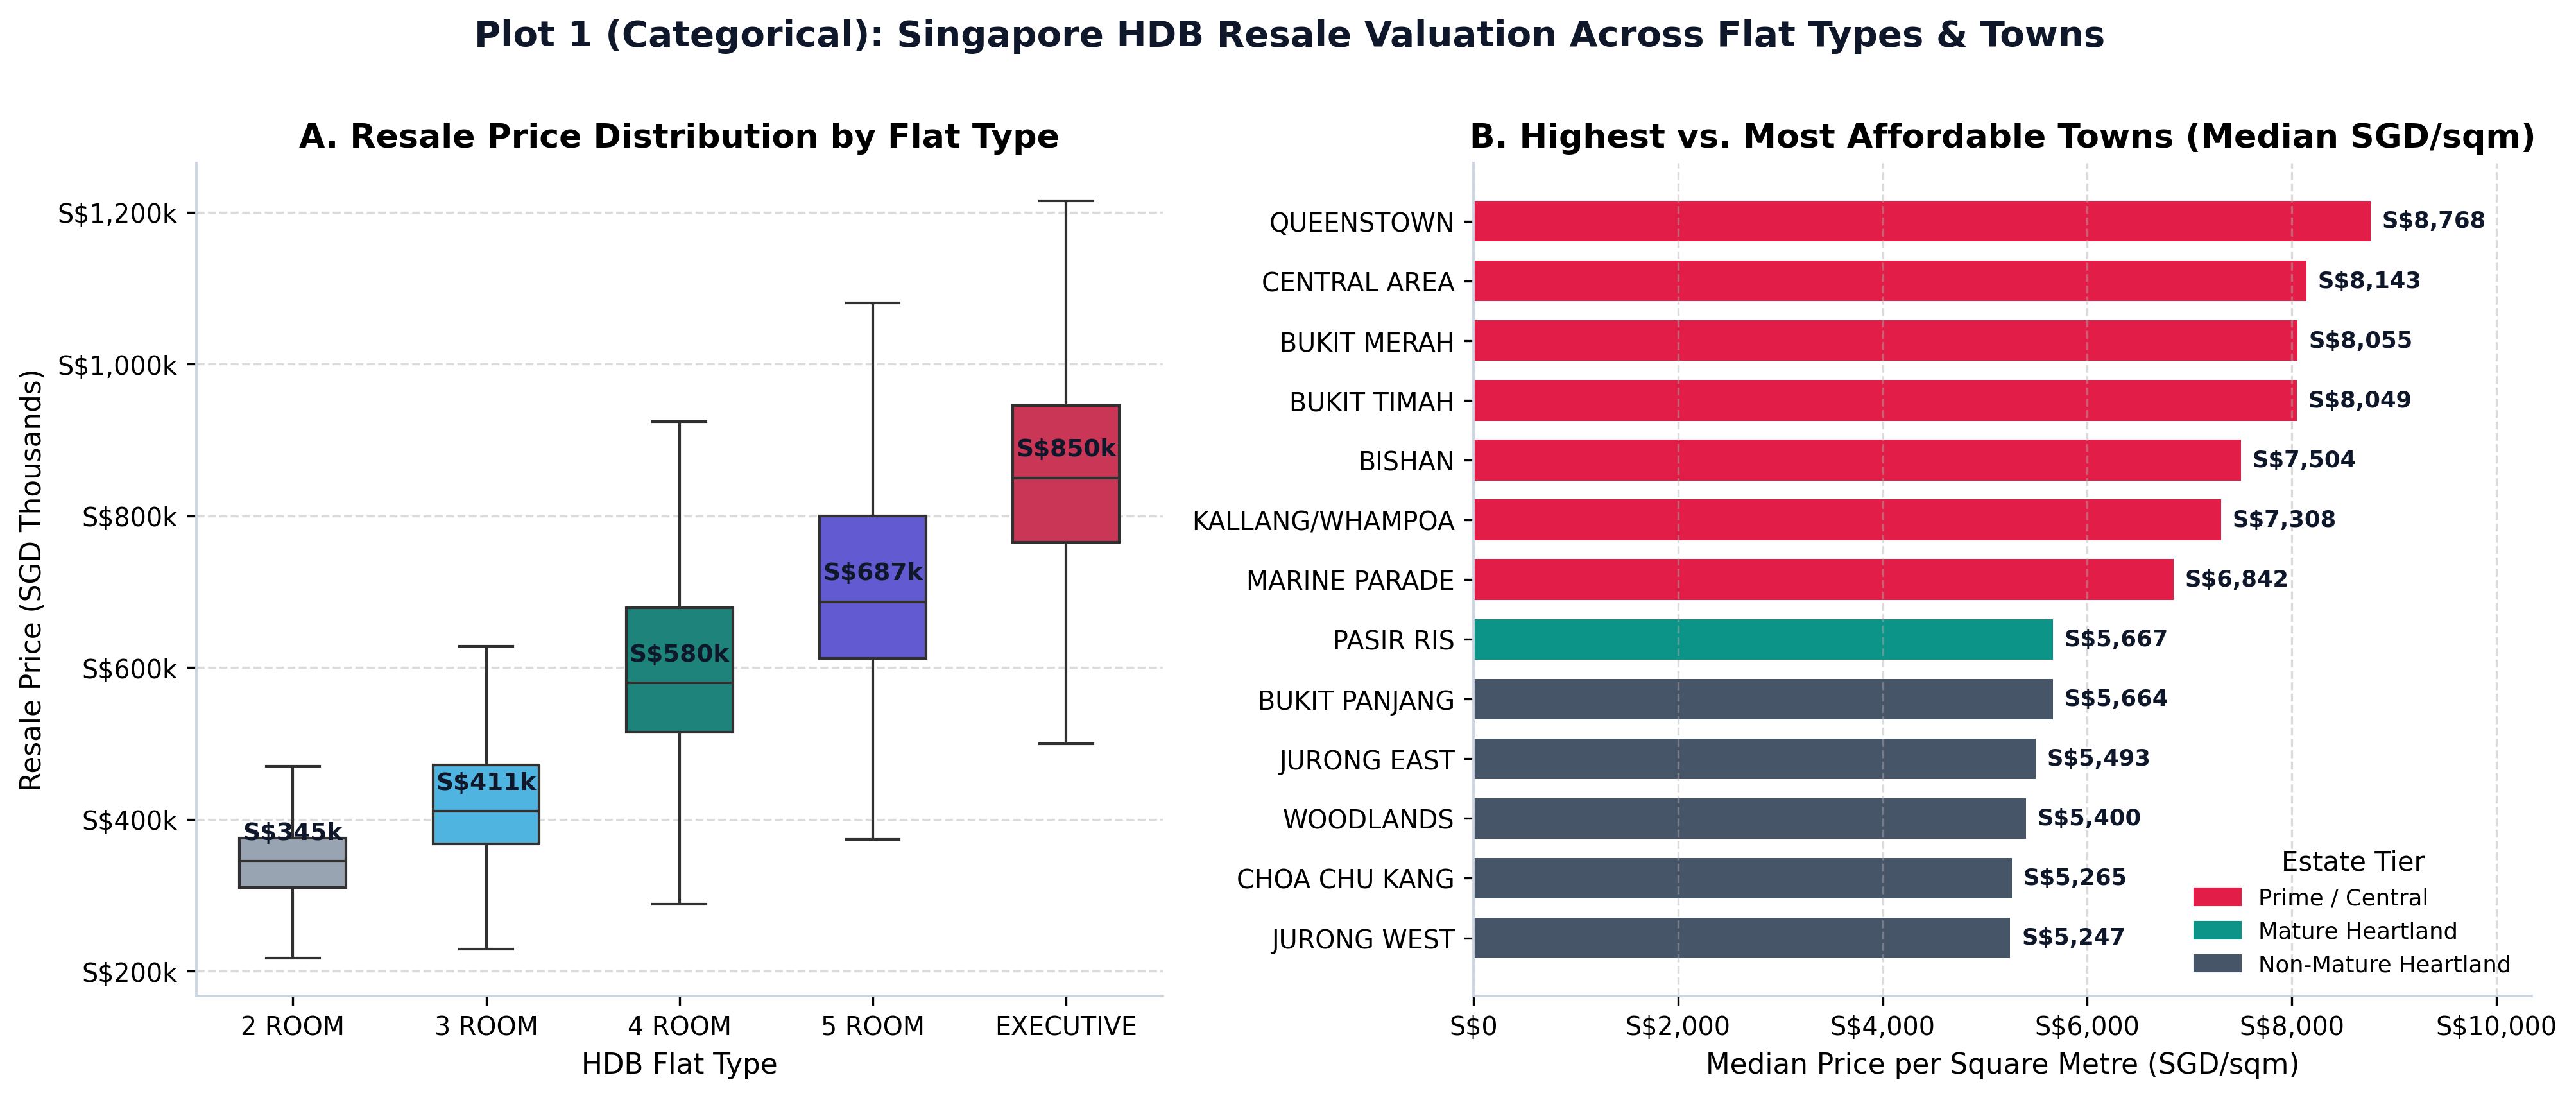


P2 (outputs/plot2_statistical_corr_lease_decay.png):


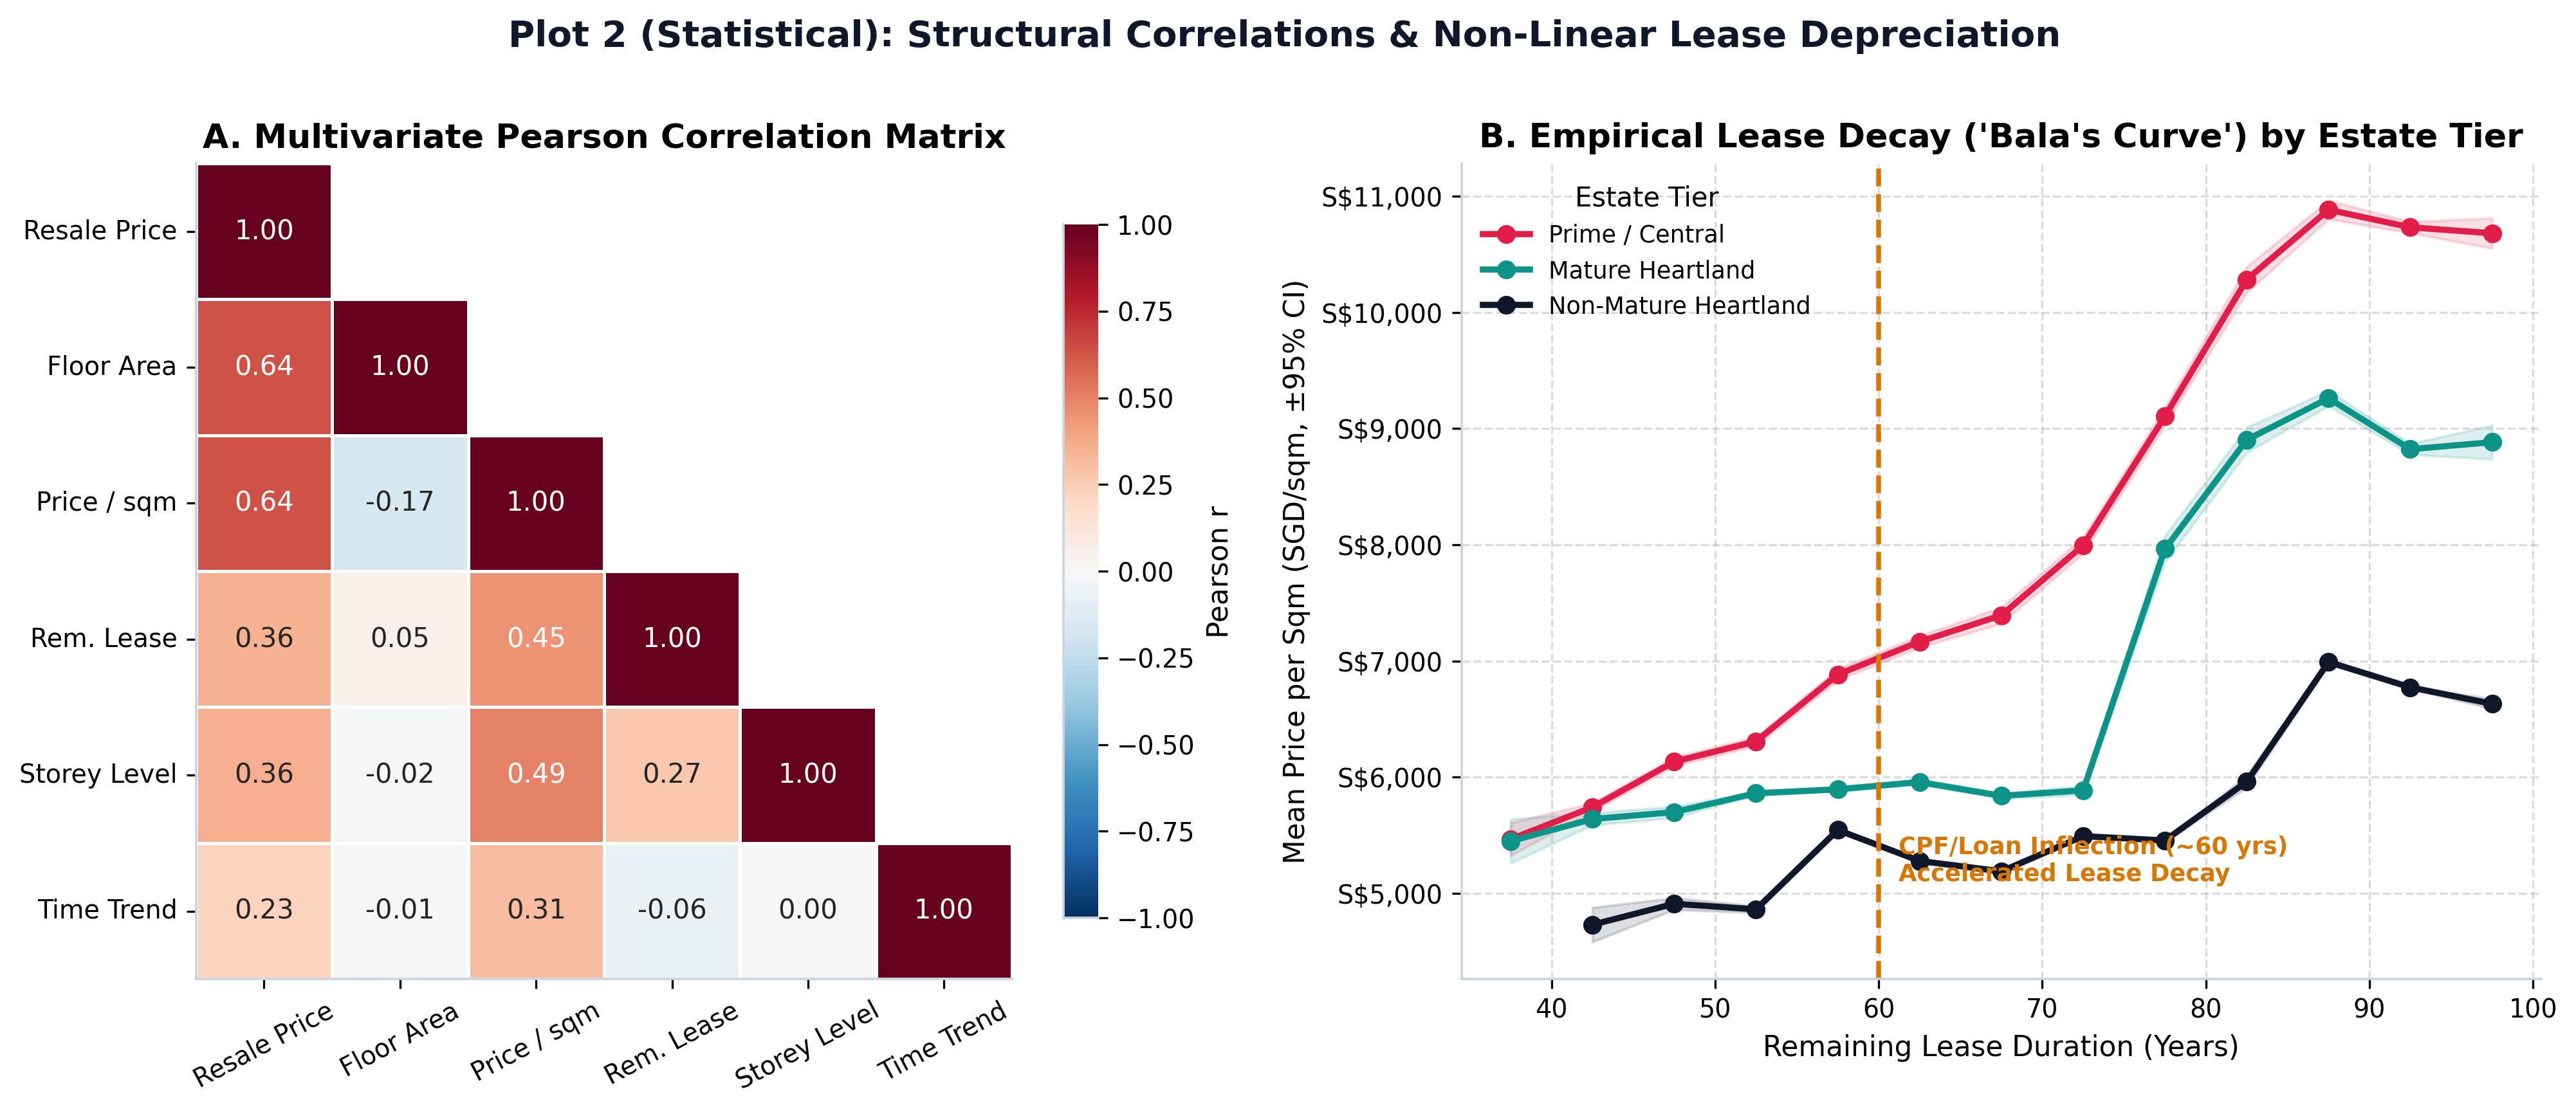


P3 (outputs/plot3_clustering_evaluation_pca.png):


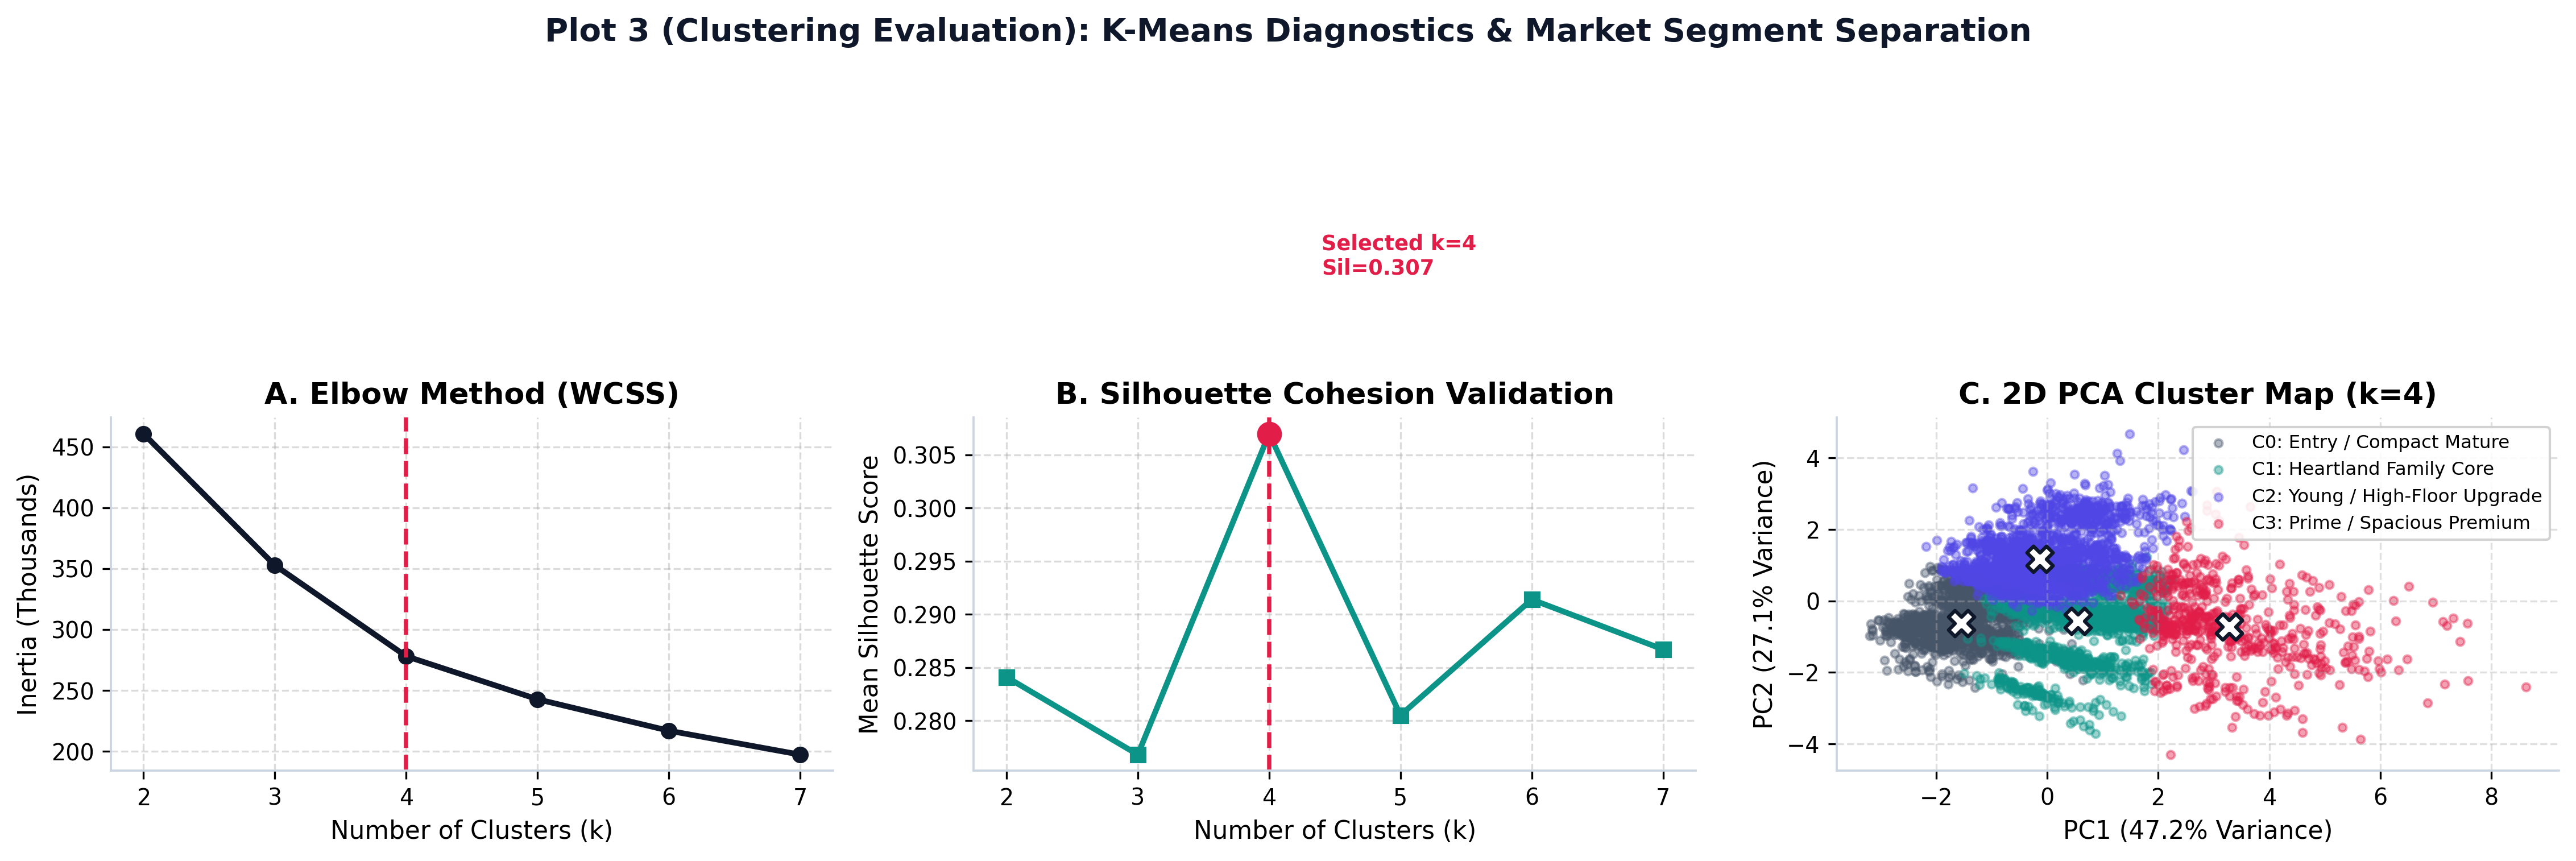


P4 (outputs/plot4_relational_line_fitting.png):


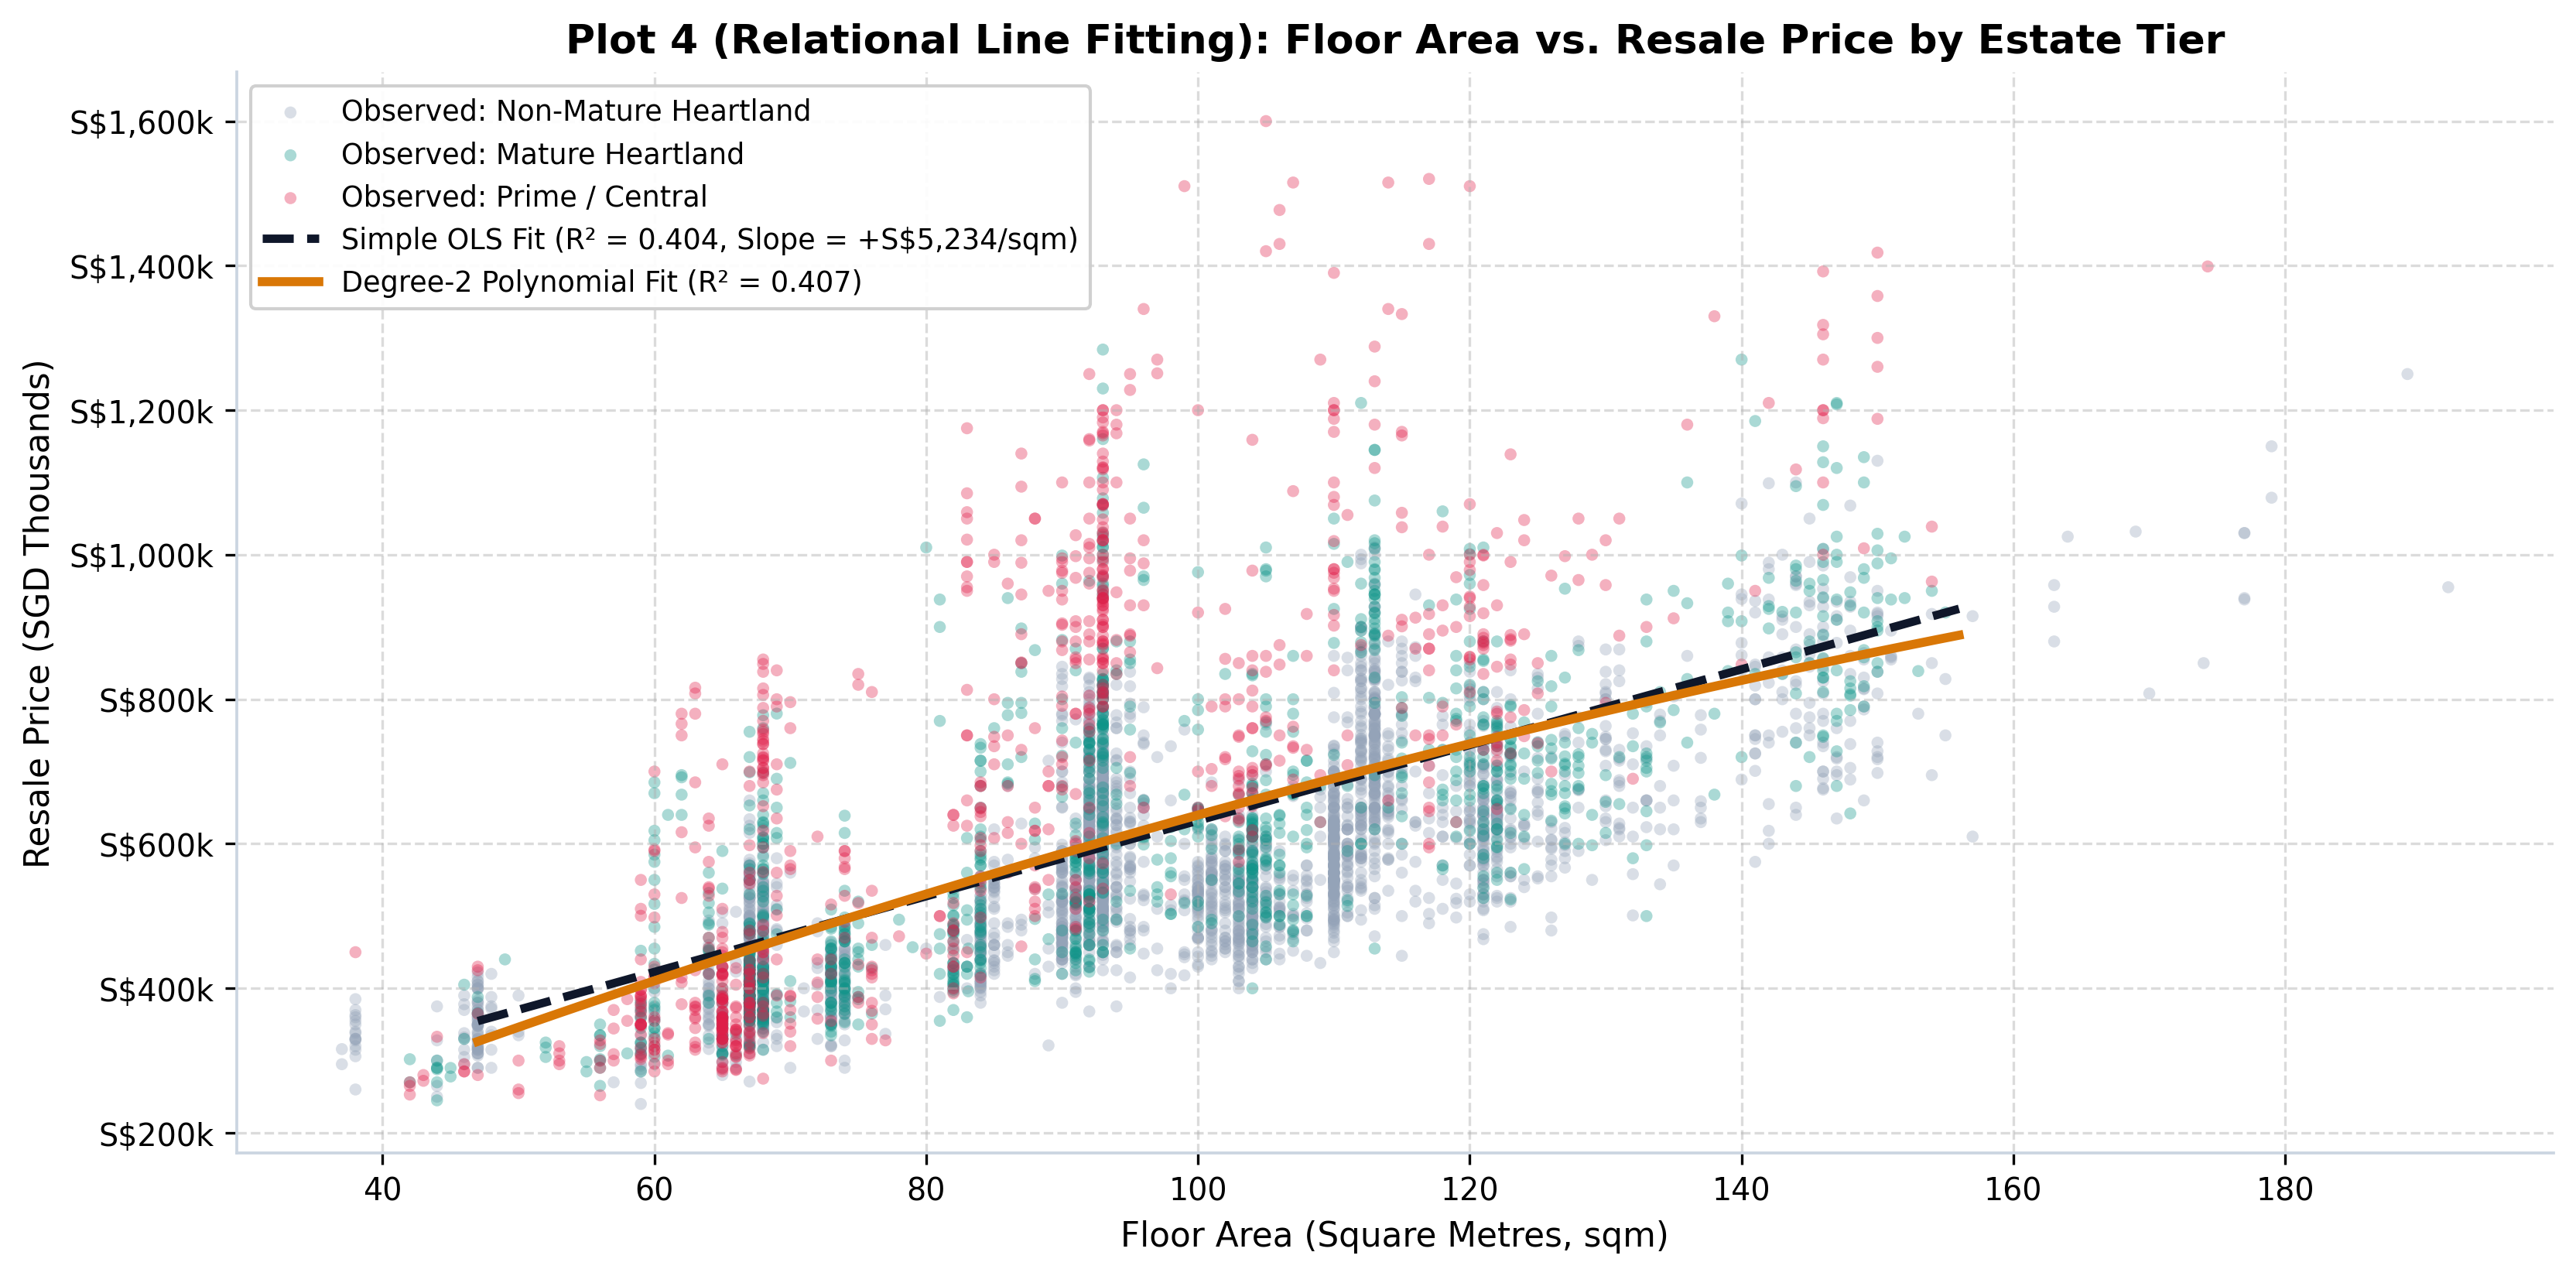


P5 (outputs/plot5_ml_model_diagnostics.png):


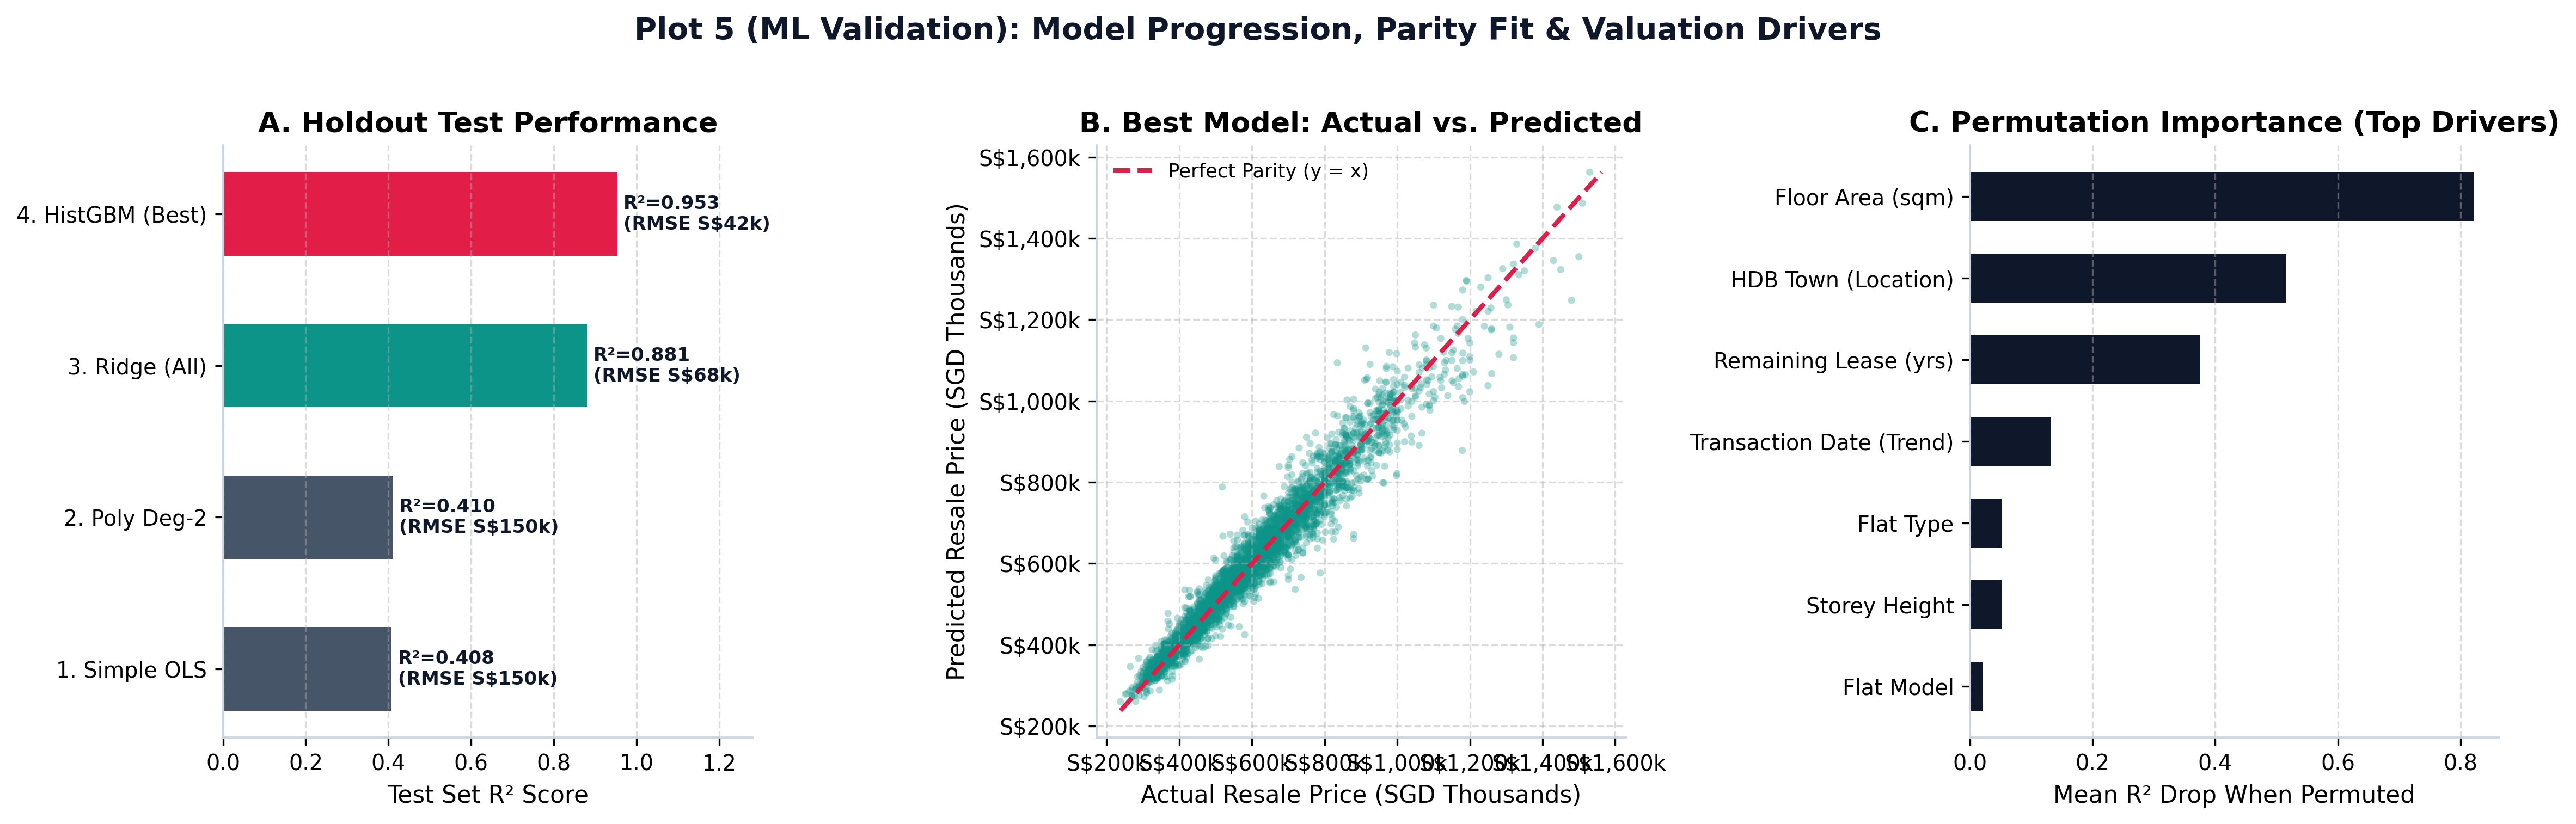

In [8]:
# 1. Run the entire end-to-end pipeline
results = run_full_pipeline(output_dir="outputs")

# 2. Display the generated visual assets directly in the notebook
from IPython.display import Image, display

print("\n=== DISPLAYING PIPELINE VISUALIZATIONS ===")
for plot_name, plot_path in results["plots"].items():
    print(f"\n{plot_name.upper()} ({plot_path}):")
    display(Image(plot_path))